# 01 · Building the Analysis Dataset

Phase 1 (`00_data_exploration.ipynb`) figured out what's in the raw files. This notebook turns them into
three tidy tables in `data/processed/`:

| File | What it is | Used for |
|---|---|---|
| `sales_all.parquet` | every unique 2019–2025 sale of **any** property type, with the sale-year tax-roll record, GIS features, coordinates, and both flood maps | anything; nothing filtered, only flagged |
| `sales_sf.parquet` | clean single-family sales | Part 1 (price model), Part 2 (flood-zone DiD) |
| `sales_condo.parquet` | clean condo-unit sales | **Part 3 (new): Florida's condo safety law + Ian** |

All logic lives in `src/build_sales.py`; this notebook runs it and explains **why** each decision was made.
Three decisions here changed the data in ways Phase 1 didn't anticipate (sections 2, 4, 5).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import build_sales as bs

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
FIG = ROOT / "figures"

# Chart style: one shared look for every figure in the project
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"     # categorical slots 1-3 (validated CVD-safe set)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "lines.linewidth": 2, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})

def event(ax, date, label, y=0.98):
    ax.axvline(pd.Timestamp(date), color=INK2, lw=1, ls=(0, (3, 3)))
    ax.text(pd.Timestamp(date), y, " " + label, transform=ax.get_xaxis_transform(),
            color=INK2, fontsize=8.5, va="top")

In [2]:
%%time
out = bs.build()          # ~30 s: reads 8 SDF files, 7 tax rolls, GIS parcels, two flood maps
sales, sf, condo = out["sales_all"], out["sf"], out["condo"]

Loading sales ...


  580,066 unique sales 2019-2025
Loading 7 tax rolls ...


  tax-roll match: 0.9983 (fallback 24,762)
Attaching GIS + flood zones ...


/Users/lukecrater/Lee-County-Home-Prices-What-Drives-Value-and-What-Did-Hurricane-Ian-Change-/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined
  return ogr_read(


  GIS match: 0.8822



single_family: 105,234 clean sales
                                                       rows  removed
all sales 2019-2025                                  580066        0
property class = single_family                       206509   373557
improved (not vacant land)                           204028     2481
qualified arm's-length (01/02, or 03 storm-damaged)  110391    93637
single-parcel sale                                   106881     3510
tax-roll total area > 0                              106746      135
GIS heated area not > sale-time total                106718       28
valid year built (1900..sale yr)                     106717        1
price/sqft within yearly 0.5-99.5 pct                105567     1150
one sale per parcel-month                            105234      333

condo: 41,718 clean sales
                                                       rows  removed
all sales 2019-2025                                  580066        0
property class = condo                  

## 1. What `sales_all` contains

One row per unique sale (de-duplicated on `(sale_id, parcel_id)`, keeping the latest SDF file, as decided in
Phase 1). Every sale is joined to the **Jan-1 tax roll of its sale year**, so the characteristics describe the
property as it was when it sold. Parcels created mid-year fall back to the next year's roll (`nal_fallback`).

In [3]:
by_yr = sales.groupby("sale_yr").agg(
    sales=("sale_id", "size"),
    tax_roll_match=("nal_matched", "mean"),
    used_next_yr_roll=("nal_fallback", "mean"),
    gis_match=("gis_matched", "mean"),
)
by_yr.style.format({"sales": "{:,}", "tax_roll_match": "{:.1%}", "used_next_yr_roll": "{:.1%}", "gis_match": "{:.1%}"})

,sales,tax_roll_match,used_next_yr_roll,gis_match
sale_yr,,,,
2019,"68,417",100.0%,0.7%,90.9%
2020,"76,003",100.0%,0.7%,89.6%
2021,"115,170",100.0%,2.4%,88.0%
2022,"92,197",100.0%,8.1%,89.1%
2023,"80,786",100.0%,9.8%,91.7%
2024,"79,405",100.0%,7.1%,84.4%
2025,"68,088",98.6%,0.0%,83.4%


In [4]:
# Property mix of all 2019-2025 sales (qualified, improved, single-parcel only) -- the CRE classes
# are kept in sales_all for later modules even though Parts 1-3 focus on homes and condos.
q = sales[sales["qual_cd"].isin(["01", "02"]) & (sales["vac_imp"] == "I") & ~sales["multi_parcel"]]
q.groupby("property_class").agg(sales=("sale_id", "size"), median_price=("sale_price", "median")) \
 .sort_values("sales", ascending=False).style.format({"sales": "{:,}", "median_price": "${:,.0f}"})

,sales,median_price
property_class,,
single_family,"103,509","$354,500"
condo,"42,112","$255,000"
vacant,"35,340","$363,000"
mobile_home,"6,394","$125,000"
multifamily_small,"4,334","$345,000"
commercial,"1,890","$800,000"
coop,"1,382","$106,750"
industrial,"1,188","$380,250"
other,609,"$200,000"


## 2. Decision: multi-parcel bundles are found by **deed**, not by sale code

Phase 1 planned to drop sales coded **05** (multi-parcel). But some bundles aren't coded 05. When one deed
(`clerk_no`, the county clerk's instrument number) transfers several parcels, **each parcel's row repeats the
whole bundle price**. Treating those as single-home prices would inflate them.

In [5]:
raw = sales.assign(n_parcels_on_deed=sales.groupby("clerk_no")["parcel_id"].transform("nunique"))
q01 = raw[raw["qual_cd"] == "01"]
bundled = q01[q01["n_parcels_on_deed"] > 1]
print(f"Qualified (01) sales on a multi-parcel deed: {len(bundled):,} of {len(q01):,} ({len(bundled)/len(q01):.1%})")
print("Share of those deeds where every parcel shows the identical price:",
      f"{bundled.groupby('clerk_no')['sale_price'].nunique().eq(1).mean():.0%}")

Qualified (01) sales on a multi-parcel deed: 13,966 of 285,249 (4.9%)
Share of those deeds where every parcel shows the identical price: 100%


Every one of those deeds repeats one price across all its parcels: proof it's a bundle price. **Rule:**
`multi_parcel = qual_cd == "05" OR the deed covers more than one parcel`. The count is done on the full
2018–2026 file so deeds that straddle the window edges are still caught.

## 3. Decision: square footage. The tax roll's `LivingArea` is **not** living area

Phase 1 read `LivingArea` as heated living space. A sanity check said otherwise: median single-family
price per sq ft came out near **$88** in 2019, far below what Lee County homes sell for. Comparing it with the
two area fields in the county GIS layer settles it:

In [6]:
import pyogrio
gdb = next(bs.RAW.glob("lee_gis/parcels/**/*.gdb"))
areas = pyogrio.read_dataframe(gdb, layer="ParcelPointsData", columns=["STRAP", "TOTALAREA", "HEATEDAREA"],
                               read_geometry=False).rename(columns={"STRAP": "parcel_id"})
chk = sf[sf["sale_yr"] == 2023].merge(areas, on="parcel_id")[["total_area", "TOTALAREA", "HEATEDAREA"]]
pd.DataFrame({
    "median sq ft": chk.median(),
    "corr. with tax-roll LivingArea": chk.corr()["total_area"],
}).rename(index={"total_area": "tax roll LivingArea", "TOTALAREA": "GIS total area", "HEATEDAREA": "GIS heated area"}).round(3)

,median sq ft,corr. with tax-roll LivingArea
tax roll LivingArea,2946.0,1.000
GIS total area,2949.0,0.999
GIS heated area,1726.0,0.822


For single-family homes `LivingArea` matches the GIS **total area under roof** almost exactly (corr ≈ 0.999):
garage, lanai, and porches included. Heated area is about 60% of that. (For condos the two are identical,
since units have no garage or lanai.)

**Rule:** rename it `total_area`, and compute **price per sq ft on heated area** (`heated_area`, from GIS), the
convention used in MLS listings and appraisals. One guard: the GIS layer is a Feb-2024 snapshot, so if the
snapshot's heated area is **larger** than the sale-time total area, the home was rebuilt or expanded after the
sale and the snapshot doesn't describe what sold; those 27 single-family rows (329 condo) are dropped.

## 4. Decision: impute heated area for recent new construction (don't drop it)

Homes on parcels created after the GIS snapshot have no heated area. Dropping them looked harmless, until
breaking the gap down by year:

In [7]:
pre = sales[(sales["property_class"] == "single_family") & (sales["vac_imp"] == "I")
            & sales["qual_cd"].isin(["01", "02"]) & ~sales["multi_parcel"] & (sales["total_area"] > 0)]
pre = pre.assign(no_heated_area=~(pre["heated_area"] > 0), new_build=pre["year_built"] >= pre["sale_yr"] - 1)
pd.DataFrame({
    "share missing heated area": pre.groupby("sale_yr")["no_heated_area"].mean(),
    "...of which new builds": pre[pre["no_heated_area"]].groupby("sale_yr")["new_build"].mean(),
}).T.style.format("{:.0%}")

sale_yr,2019,2020,2021,2022,2023,2024,2025
share missing heated area,5%,5%,5%,2%,3%,16%,23%
...of which new builds,6%,9%,4%,6%,42%,71%,71%


The gap jumps to **16% of 2024 sales and 23% of 2025 sales**, and much of it is new construction. Dropping
those rows would quietly remove the post-Ian building boom from exactly the period the DiD compares.

**Rule:** fill missing heated area as `total_area` × the median heated/total ratio of homes in the same
**neighborhood** (falling back to market area, then county-wide). Imputed rows are flagged `heated_imputed`
so later models can run with and without them. How accurate is it? Test it on homes built since 2015 whose
heated area *is* known:

In [8]:
known = sf[~sf["heated_imputed"]].copy()
ratio = known["heated_area"] / known["total_area"]
nbhd_ratio = ratio.groupby(known["neighborhood"]).transform("median")
test = known["year_built"] >= 2015
err = ((known["total_area"] * nbhd_ratio) / known["heated_area"] - 1).abs()[test]
print(f"Homes tested: {test.sum():,}   median abs error: {err.median():.1%}   90th pct: {err.quantile(.9):.1%}")

Homes tested: 16,701   median abs error: 7.9%   90th pct: 28.2%


A typical error under 10% is fine for a size variable in a price model. (It's an in-sample check: each
home's own ratio is part of its neighborhood median, so the true error is slightly higher.)

## 5. Cleaning funnels

Same recipe for single-family and condo sales. Each step and why:

| Step | Why |
|---|---|
| property class | `DORland` 001 single-family / 004 condo |
| improved | `vac_imp = I`; vacant-lot sales aren't home sales |
| qualified 01/02, or 03 storm-damaged | arm's-length only; removes $100 deeds, family transfers, foreclosures, pending codes. Homes sold **storm-damaged** are arm's-length but coded 03 with `sale_chg_cd = 5`; they're kept and flagged `damaged_sale` (see `02_eda_single_family.ipynb` §5a: dropping them causes survivor bias) |
| single-parcel | bundle prices can't be attributed to one property (section 2) |
| total area > 0, GIS area not larger than sale-time area | the property must be described as it was at sale (sections 3–4) |
| valid year built | `ActYearBuilt` between 1900 and the sale year; 0 means a missing or demolished structure |
| price/sq ft trimmed at 0.5 / 99.5 percentile **within each year** | removes data errors and partial-interest sales; done per year so the 2021–22 run-up isn't mistaken for outliers. Bounds come from undamaged sales; damaged sales get only the upper bound plus a $10k floor, since a low $/sq ft is the point for them |
| one sale per parcel-month | re-recorded / corrective deeds |

In [9]:
pd.concat({"single family": out["funnel_sf"], "condo": out["funnel_condo"]}, axis=1).fillna(0).astype(int)

single family           condo        
                                                            rows removed    rows removed
all sales 2019-2025                                       580066       0  580066       0
property class = single_family                            206509  373557       0       0
improved (not vacant land)                                204028    2481   79307     953
qualified arm's-length (01/02, or 03 storm-dama...        110391   93637   43456   35851
single-parcel sale                                        106881    3510   43440      16
tax-roll total area > 0                                   106746     135   43281     159
GIS heated area not > sale-time total                     106718      28   42952     329
valid year built (1900..sale yr)                          106717       1   42252     700
price/sqft within yearly 0.5-99.5 pct                     105567    1150   41757     495
one sale per parcel-month                                 105234     333   41718      39
property class = condo                                         0       0   80260  499806

Single-family: **105k clean sales**, 3.2k of them storm-damaged (Phase 1 estimated 107k before the bundle, area,
and outlier rules). Condo: **42k clean sales**. Qualification is the biggest cut by far: almost half of all deeds aren't
market sales.

A notable condo row: 700 sales fail "valid year built". Those are mostly units whose building has
`ActYearBuilt = 0` on the roll in that year, typically buildings under construction or destroyed and being
rebuilt after Ian.

## 6. First look at the clean data

These charts are **sanity checks and previews**, not results: no controls yet. They do show the
three stories the project is built around.

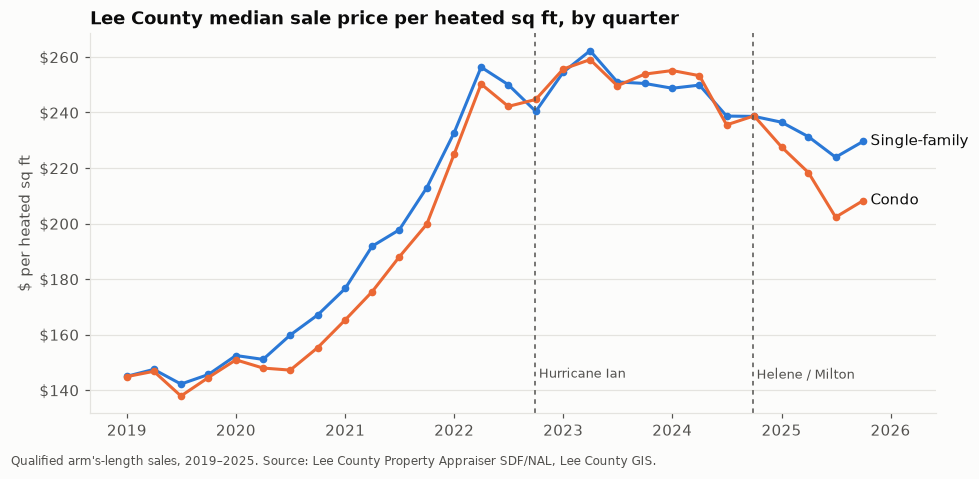

In [10]:
def q_median(df, by=None):
    g = [pd.Grouper(key="sale_date", freq="QS")] + ([by] if by else [])
    return df.groupby(g)["price_per_sqft"].agg(["median", "size"]).reset_index()

fig, ax = plt.subplots(figsize=(9, 4.2))
for df, label, color in [(sf, "Single-family", C1), (condo, "Condo", C2)]:
    m = q_median(df)
    ax.plot(m["sale_date"], m["median"], color=color, marker="o", ms=4)
    ax.text(m["sale_date"].iloc[-1] + pd.Timedelta(days=25), m["median"].iloc[-1], label,
            color=INK, va="center", fontsize=9.5)
event(ax, "2022-09-28", "Hurricane Ian", y=0.12)
event(ax, "2024-09-26", "Helene / Milton", y=0.12)
ax.set_title("Lee County median sale price per heated sq ft, by quarter")
ax.set_ylabel("$ per heated sq ft")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlim(right=pd.Timestamp("2026-06-01"))
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.text(0.01, -0.02, "Qualified arm's-length sales, 2019–2025. Source: Lee County Property Appraiser SDF/NAL, Lee County GIS.",
         color=INK2, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "01_price_per_sqft_sf_condo.png", dpi=200, bbox_inches="tight")

Both markets ran up ~70% from 2019 to 2022 (low rates, pandemic in-migration), then flattened. Condos peaked
in 2023 and have fallen faster since. The question for Parts 2–3 is **how much of the post-2022 movement is
Ian / flood risk / regulation vs. the statewide rate shock**, which is why every comparison needs a control group.

### Preview, Part 2: flood-zone homes vs. the rest

Treatment = inside the high-risk Special Flood Hazard Area on the **2008** flood map (the map in force when Ian hit).

,outside SFHA,in SFHA,flood-zone premium
before Ian,171.9,212.9,41.0
after Ian,235.2,271.1,35.9


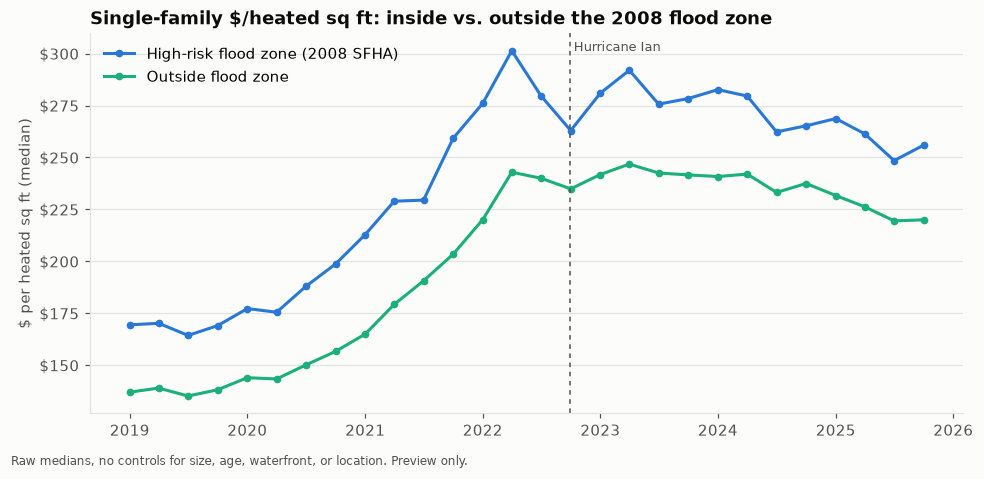

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
m = q_median(sf, "sfha_2008")
for flag, label, color in [(True, "High-risk flood zone (2008 SFHA)", C1), (False, "Outside flood zone", C3)]:
    d = m[m["sfha_2008"] == flag]
    ax.plot(d["sale_date"], d["median"], color=color, marker="o", ms=4, label=label)
event(ax, "2022-09-28", "Hurricane Ian")
ax.set_title("Single-family $/heated sq ft: inside vs. outside the 2008 flood zone")
ax.set_ylabel("$ per heated sq ft (median)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.text(0.01, -0.02, "Raw medians, no controls for size, age, waterfront, or location. Preview only.", color=INK2, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "01_preview_flood_zone.png", dpi=200, bbox_inches="tight")

g = sf.groupby(["post_ian", "sfha_2008"])["price_per_sqft"].median().unstack()
g.index = ["before Ian", "after Ian"]; g.columns = ["outside SFHA", "in SFHA"]
g["flood-zone premium"] = g["in SFHA"] - g["outside SFHA"]
g.round(1)

Flood-zone homes sell at a **premium** per sq ft, because flood zones here are mostly where the water is
(canals, bay, Gulf access). In the raw medians that premium shrank from about **$41 to $36** per sq ft
after Ian, roughly −$5 against a market that rose ~$63. That change in the last column is a raw, uncontrolled
"difference in differences". It's small enough that controls could erase it, or uncover a larger effect
hidden by composition. (It turns out to be the latter: see `02_eda_single_family.ipynb` §5b.) Part 2 has to test whether it survives controls for waterfront
type, size, age, and neighborhood, and whether it's driven by storm damage itself (`sale_chg_cd = 5`,
`disaster_year`).

### Preview, Part 3 (new): the condo law

In May 2022, eleven months after the Surfside collapse, Florida passed **SB 4-D**. It requires
milestone structural inspections and structural-integrity reserve studies (SIRS) for condo buildings
**three stories or taller**, with fully funded reserves for those components starting with budgets after
**Dec 31, 2024**. Buildings under three stories are exempt.

That cutoff splits the county's condos into a natural treatment group (3+ stories, facing special assessments
and higher HOA dues) and a comparison group (1–2 stories) hit by the same rates and the same hurricane.
*(Exact statutory dates and later amendments, e.g. 2023's SB 154 and 2025's HB 913, to be verified in Phase 6.)*

height
1–2 stories (exempt)              26701
3+ stories (covered by SB 4-D)    14852
unknown                             165


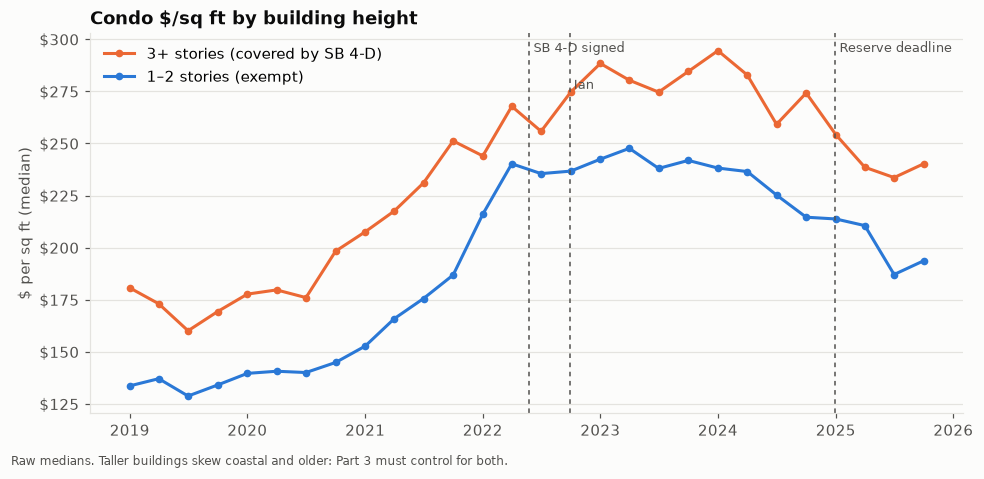

In [12]:
condo = condo.assign(height=np.where(condo["stories"] >= 3, "3+ stories (covered by SB 4-D)",
                             np.where(condo["stories"] >= 1, "1–2 stories (exempt)", "unknown")))
print(condo["height"].value_counts().to_string())

fig, ax = plt.subplots(figsize=(9, 4.2))
m = q_median(condo[condo["height"] != "unknown"], "height")
for label, color in [("3+ stories (covered by SB 4-D)", C2), ("1–2 stories (exempt)", C1)]:
    d = m[m["height"] == label]
    ax.plot(d["sale_date"], d["median"], color=color, marker="o", ms=4, label=label)
event(ax, "2022-05-26", "SB 4-D signed", y=0.98)
event(ax, "2022-09-28", "Ian", y=0.88)
event(ax, "2024-12-31", "Reserve deadline", y=0.98)
ax.set_title("Condo $/sq ft by building height")
ax.set_ylabel("$ per sq ft (median)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.text(0.01, -0.02, "Raw medians. Taller buildings skew coastal and older: Part 3 must control for both.", color=INK2, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "01_preview_condo_height.png", dpi=200, bbox_inches="tight")

In [13]:
# Volume tells its own story: sales count per year by height group, indexed to 2019 = 100
vol = condo[condo["height"] != "unknown"].groupby(["sale_yr", "height"]).size().unstack()
(vol / vol.loc[2019] * 100).round(0).astype(int).T

sale_yr,2019,2020,2021,2022,2023,2024,2025
height,,,,,,,
1–2 stories (exempt),100,109,148,95,80,62,63
3+ stories (covered by SB 4-D),100,107,156,84,66,61,62


## 7. Output columns (data dictionary)

| Column | Source | Meaning |
|---|---|---|
| `sale_id`, `parcel_id`, `clerk_no` | SDF | sale ID, 17-char STRAP parcel ID, deed instrument number |
| `sale_price`, `sale_date`, `sale_yr`, `sale_mo` | SDF | price; date = 1st of sale month (no day available) |
| `post_ian` | derived | sale month ≥ Oct 2022 |
| `qual_cd`, `vac_imp`, `sale_chg_cd`, `multi_parcel` | SDF / derived | qualification, vacant/improved, change code (5 = disaster), bundle flag |
| `dor_code`, `property_class` | NAL | DOR land use, grouped (single_family, condo, multifamily, commercial, …) |
| `just_value`, `land_value` | NAL | appraiser's market value on Jan 1 of sale year |
| `total_area` | NAL `LivingArea` | **total** area under roof (sq ft) |
| `heated_area`, `heated_imputed` | GIS / derived | heated sq ft; flag if imputed (section 4) |
| `year_built`, `eff_year_built`, `age_at_sale` | NAL / derived | actual & effective (renovation-adjusted) year built |
| `quality`, `construction_class`, `building_count`, `res_units` | NAL | appraiser quality grade etc. |
| `market_area`, `neighborhood`, `block_group`, `city`, `zip` | NAL | location codes (block group joins to Census) |
| `disaster_code`, `disaster_year` | NAL | disaster value reduction on the roll (2022 = Ian, 2024 = Helene/Milton) |
| `acres`, `waterfront`, `beds`, `baths`, `pool`, `boat_dock`, `seawall`, `garage`, `stories`, `zoning` | GIS (Feb 2024) | current-state features |
| `x_ft`, `y_ft`, `lon`, `lat` | GIS | parcel point (State Plane ft / WGS84) |
| `flood_zone_2008`, `sfha_2008` | 2008 FIRM | zone & high-risk flag **when Ian hit** (`X500` = 0.2% annual chance) |
| `flood_zone_now`, `sfha_now` | FEMA NFHL | zone & flag on the current map (effective Nov 2022) |
| `price_per_sqft`, `log_price` | derived | price / heated sq ft; ln(price) |

## 8. Summary and next phase

**Built:** 580k sales across all property types → **105k clean single-family** and **42k clean condo** sales,
each with sale-time characteristics, location, amenities, and both flood maps.

**Changed from the Phase 1 plan:**
1. Bundled sales are detected by **deed**, which catches ~14k qualified rows that code 05 misses.
2. `LivingArea` is **total** area under roof. Price per sq ft now uses **heated** area from GIS.
3. Missing heated area (mostly 2024–25 new builds) is **imputed and flagged**, not dropped, to avoid
   biasing the post-Ian sample.
4. *(Added in Phase 3)* Homes sold **storm-damaged** (qual code 03 + disaster change code) are kept and
   flagged `damaged_sale`; the 01/02-only rule silently dropped the hardest-hit flood-zone homes.

**Known limitations:** GIS amenities (pool, dock, beds/baths) are a 2024 snapshot; sale dates are month-only;
condo height comes from the building's current max stories.

**Next, Phase 3:** exploratory analysis of the single-family market (price drivers, maps, waterfront and
flood-zone patterns), then the price model (Part 1).